---
title: "Lecture 9: Derived Distributions"
author: "Jamie Haddock"
format:
    revealjs:
        output-file: Lecture9_slides
        slide-number: true
        preview-links: auto
        logo: figs/hmc.png
        css: input/slides.css
        incremental: true
        smaller: true
        code-fold: true
        embed-resources: true
        html-math-method: katex
        slide-level: 3
    html:
        code-fold: true
        embed-resources: true
        output-file: Lecture9
        code-links:
          - text: "Open in Colab"
            href: "https://colab.research.google.com/github/jamiehadd/Math-151-Probability/blob/main/09_derived-distributions.ipynb"
            icon: "laptop"
    pdf:
        documentclass: article
        toc: true
        number-sections: true
        output-file: Lecture9
        geometry:
          - top=1in
          - left=1in
          - bottom=1in
          - right=1in
format-links: false
jupyter: python3
colab:
  gh-user: "jamiehadd"
  gh-repo: "Math-151-Probability"
filters:
  - input/remove-pause.lua
  - colab
execute:
  echo: true
  eval: true
---

# Derived Distributions

## The Two-Step Process

We want the PDF of $Y = g(X)$ for a continuous RV $X$ with known PDF $f_X$.

**Step 1.** Find the CDF of $Y$:
$$F_Y(y) = P(Y \le y) = P(g(X) \le y) = \int_{\{x \mid g(x) \le y\}} f_X(x)dx$$
by translating the event $\{g(X)\le y\}$ into an event about $X$ and
using $f_X$ to compute its probability.

**Step 2.** Differentiate:
$$f_Y(y) = \frac{d}{dy} F_Y(y)$$

. . .

**Why not go directly PMF-style?** In the discrete case, if $g$ is
invertible we can write $p_Y(y) = p_X(g^{-1}(y))$ directly. We need to go through the Fundamental Law of Calculus/differentiate the CDF route because we can only say that the *mass* of events are equal, not the density!

### Example: $X \sim \text{Uniform}(0,1)$, $Y = \sqrt{X}$

$$F_Y(y) = P(\sqrt X \le y) = P(X \le y^2) = y^2, \qquad 0 \le y \le 1$$

. . .

$$f_Y(y) = \frac{d}{dy}\, y^2 = 2y, \qquad 0 \le y \le 1$$

. . .

![](figs/CDF_to_PDF.jpeg){width=50%}


## Linear Case: $Y = aX + b$

Applying the two-step process for $a > 0$:
$$F_Y(y) = P(aX + b \le y) = P\Big(X \le \frac{y-b}{a}\Big) = F_X\Big(\frac{y-b}{a}\Big)$$

Differentiating (chain rule), and handling $a<0$ the same way, gives the
general formula:
$$f_Y(y) = \frac{1}{|a|}\, f_X\Big(\frac{y-b}{a}\Big)$$

![](figs/linear_derived.jpeg)

### Example: $X \sim \mathcal{N}(\mu, \sigma^2)$, $Y = aX + b$

Plugging the Normal PDF into the linear-case formula gives
$$f_Y(y) = \frac{1}{|a|\sigma\sqrt{2\pi}} \exp\left(-\frac{1}{2}\left(\frac{\frac{y-b}{a}-\mu}{\sigma}\right)^2\right)$$
which is exactly the $\mathcal{N}(a\mu + b,\; a^2\sigma^2)$ density.

. . .

We saw this previously, using the PDF of a monotonic function of a RV theorem!

### Exercise

::: {.callout-caution}
## Exercise

$X$ is Exponential($\lambda$), and $Y = aX + b$ with $a > 0$.

- What is the PDF of $Y$?
- Is $Y$ exponential?
:::

### Exercise -- Solution

For $a>0$: $x = \frac{y-b}{a} \ge 0 \iff y \ge b$, so
$$f_Y(y) = \frac{1}{a} \lambda\, e^{-\lambda (y-b)/a}, \qquad y \ge b$$
$$F_Y(y) = 1 - e^{-\lambda (y-b)/a}, \qquad y \ge b$$

. . .

**Is $Y$ exponential?** Only if $b = 0$ -- then $Y \sim \text{Exponential}(\lambda/a)$
exactly. If $b \ne 0$, $Y$ has the exponential *shape* but shifted to start
at $b$ instead of $0$: it's memoryless from $b$ onward, not from $0$, so
it is not itself an Exponential random variable.

(If $a<0$ instead, the same formula applies but the support flips to
$y \le b$.)

---

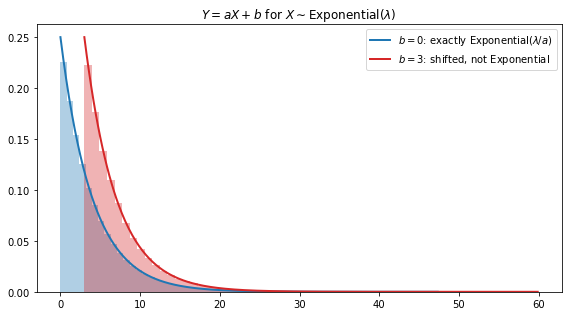

In [1]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(2)
lam, a = 0.5, 2.0

fig, ax = plt.subplots(figsize=(8, 4.5))
for b, color in [(0.0, "C0"), (3.0, "C3")]:
    X = rng.exponential(1 / lam, 200_000)
    Y = a * X + b
    y = np.linspace(b, Y.max(), 400)
    fy = (lam / a) * np.exp(-lam * (y - b) / a)
    ax.hist(Y, bins=60, density=True, alpha=0.35, color=color)
    label = r"$b=0$: exactly Exponential($\lambda/a$)" if b == 0 else r"$b=3$: shifted, not Exponential"
    ax.plot(y, fy, color=color, lw=2, label=label)

ax.set_title(r"$Y = aX+b$ for $X\sim\mathrm{Exponential}(\lambda)$")
ax.legend()
plt.tight_layout()
plt.show()

## Recall: Monotonic Case

The linear case generalizes: if $g$ is **strictly monotonic** and
differentiable, with inverse $h = g^{-1}$,
$$f_Y(y) = f_X(h(y))\, |h'(y)|$$

. . .

Specializing to $g(x) = ax+b$: $h(y) = \frac{y-b}{a}$, $h'(y) = \frac{1}{a}$,
recovering exactly the linear-case formula above.

## Review of Proof

The formula follows from the same two-step process, using that
monotonicity lets us rewrite the event $\{g(X) \le y\}$ as an event about
$X$ alone:
$$\{g(X) \le y\} = \{X \le h(y)\}$$
if $g$ is increasing, or
$\{X \ge h(y)\}$ if $g$ is decreasing.

. . .

![](figs/event_equivalence.jpeg){width=50%}

## Functions of Two Random Variables

Same two-step process applies: For $Z = g(X,Y)$, jointly continuous $X,Y$:

**Step 1.** $F_Z(z) = P(g(X,Y) \le z) = \displaystyle\iint_{\{(x,y)\,:\,g(x,y)\le z\}} f_{X,Y}(x,y)\,dx\,dy$

**Step 2.** $f_Z(z) = \dfrac{d}{dz} F_Z(z)$

The only new wrinkle is that "the event" is now a *region* of the plane
rather than an interval of the line.

### Example: $X, Y \sim \text{Uniform}(0,1)$ independent, $Z = Y/X$

$\{Z \le z\} = \{Y \le zX\}$: the region of the unit square below the
line $y = zx$. Its area looks different depending on whether the line
exits through the top of the square or the right edge.

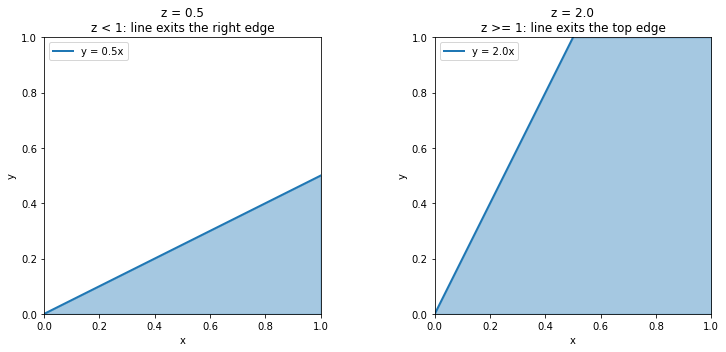

In [5]:
import numpy as np
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(11, 5))

for ax, z, title in [(axes[0], 0.5, "z < 1: line exits the right edge"),
                      (axes[1], 2.0, "z >= 1: line exits the top edge")]:
    xx = np.linspace(0, 1, 200)
    yy = np.clip(z * xx, 0, 1)
    ax.fill_between(xx, 0, yy, color="C0", alpha=0.4)
    ax.plot(xx, np.clip(z * xx, 0, 1.3), color="C0", lw=2, label=f"y = {z}x")
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.set_aspect("equal")
    ax.set_title(f"z = {z}\n{title}")
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.legend(loc="upper left")

plt.tight_layout()
plt.show()

---

Integrating the shaded area in each case:
$$F_Z(z) = \begin{cases} \dfrac{z}{2} & 0 \le z < 1 \\[4pt] 1 - \dfrac{1}{2z} & z \ge 1 \end{cases}
\qquad\Longrightarrow\qquad
f_Z(z) = \begin{cases} \dfrac12 & 0 < z < 1 \\[4pt] \dfrac{1}{2z^2} & z \ge 1 \end{cases}$$

. . .

Sanity check: $\int_0^1 \frac12\,dz + \int_1^\infty \frac{1}{2z^2}\,dz = \frac12+\frac12=1$. $\checkmark$

## Sums of Random Variables -- Convolution

### Motivation: the Discrete Case

For independent discrete RVs $X, Y$ and $Z = X+Y$:
$$
\begin{aligned}
p_Z(z) &= P(X + Y = z)
\\&= \sum_{\{(x,y) \mid x+y = z\}}P(X=x, Y=y)
\\&= \sum_x P(X=x, Y = z-x)
\\&=\sum_x p_X(x)\, p_Y(z-x)
\end{aligned}
$$

We sum over every way $x$ and $z-x$ could combine to produce the total
$z$. This is the **convolution** of $p_X$ and $p_Y$.

### The Continuous Case

Replacing sums with integrals: for independent continuous $X,Y$,
$$F_Z(z) = P(X+Y\le z) = \int_{-\infty}^{\infty} f_X(x)\, F_Y(z-x)\, dx$$
Differentiating in $z$ gives the continuous convolution formula:
$$f_Z(z) = \int_{-\infty}^{\infty} f_X(x)\, f_Y(z-x)\, dx$$

### Example: Sum of i.i.d. $\text{Uniform}(0,1)$ RVs

Suppose $X, Y \sim \text{Uniform}([0,1])$ are independent.  The PDF of $Z = X + Y$ is $$f_Z(z) = \int_{-\infty}^\infty f_X(x)f_Y(z-x)dx.$$ The integrand is nonzero (equal to 1) for $0 \le x \le 1$ and $0 \le z-x \le 1$. 

. . .

Combining these, we see the integrand is nonzero for $\max\{0,z-1\} \le x \le \min\{1,z\}$.  Thus, $$f_Z(z) = \min\{1,z\} - \max\{0,z-1\} \text{ for } 0 \le z \le 2.$$

### Example: Sum of Independent Normal RVs is Normal

If $X\sim\mathcal N(\mu_1,\sigma_1^2)$, $Y\sim\mathcal N(\mu_2,\sigma_2^2)$
independent, then
$$X+Y \sim \mathcal N(\mu_1+\mu_2,\ \sigma_1^2+\sigma_2^2)$$

<details>
<summary>Sketch</summary>

Plugging both Gaussian densities into $f_Z(z)=\int f_X(x)f_Y(z-x)\,dx$
gives an integrand of the form $\exp(-(\text{quadratic in } x))$; completing
the square in $x$ separates the integral into a constant (in $x$) factor
times a Gaussian integral over $x$ that evaluates to $1$. What's left as
a function of $z$ is exactly the $\mathcal N(\mu_1+\mu_2,\sigma_1^2+\sigma_2^2)$
density.
</details>



## Graphical Calculation of Convolutions

$f_Z(z) = \int f_X(x)\, f_Y(z-x)\, dx$ has a picture: **flip** $f_Y$
about the vertical axis, **slide** it by $z$, multiply pointwise against
$f_X$, and the shaded overlap area is $f_Z(z)$. 

![](figs/convolution.jpeg)